# Part 3: Architecture Extension

## Imports and Settings

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

from utils import *


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

set_seed(42)

Using device: cpu


## Load Data

In [3]:
X_train, y_train, X_val, y_val, X_test, y_test, train_ds, val_ds, test_ds, feature_cols, target_col, idx_to_label = load_data()

BATCH_SIZE = 64
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

criterion = nn.CrossEntropyLoss()
label_names = [idx_to_label[i] for i in range(len(idx_to_label))]

## Deep MLP

Here we define a generic deep MLP for multiple uses.

In [4]:
class DeepMLP(nn.Module):
    def __init__(self, input_dim=561, hidden_dims=[64], num_classes=6, activations="relu", dropout=0.0, batch_norm=False):
        super().__init__()

        if isinstance(activations, str):
            activations = [activations] * len(hidden_dims)
        elif len(activations) != len(hidden_dims):
            raise ValueError(f"Length of activations must match hidden_dims.")

        layers = []
        prev_dim = input_dim

        for h_dim, act_name in zip(hidden_dims, activations):
            layers.append(nn.Linear(prev_dim, h_dim))
            if batch_norm:
                layers.append(nn.BatchNorm1d(h_dim))

            act = act_name
            if act == "relu":
                layers.append(nn.ReLU())
            elif act == "tanh":
                layers.append(nn.Tanh())
            elif act == "sigmoid":
                layers.append(nn.Sigmoid())
            elif act == "gelu":
                layers.append(nn.GELU())
            elif act == "leaky_relu":
                layers.append(nn.LeakyReLU(0.1))
            else:
                raise ValueError("Unsupported activation.")

            if dropout > 0.0:
                layers.append(nn.Dropout(dropout))

            prev_dim = h_dim

        layers.append(nn.Linear(prev_dim, num_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

    def count_parameters(self):
        return sum(p.numel() for p in self.parameters() if p.requires_grad)


## Hidden Layer Widths

We keep the architecture at 1 hidden layer and vary the width $W \in \{32, 64, 128, 256\}$.

We keep the learning rate at 0.001 for now as imformed by part 2.

In [5]:
widths = [32, 64, 128, 256, 512, 1024]
width_results = []
width_histories = {}

for w in widths:
    model = DeepMLP(input_dim=561, hidden_dims=[w], num_classes=6, activations="relu").to(device)
    n_params = model.count_parameters()
    opt = torch.optim.Adam(model.parameters(), lr=0.001)

    t0 = time.perf_counter()
    hist = train_model(
        model, train_loader, val_loader, criterion, opt,
        n_epochs=50, device=device, early_stopping_patience=10, verbose_every=0
    )
    elapsed = time.perf_counter() - t0

    best_ep = hist["best_epoch"]
    n_eps = len(hist["train_loss"])
    time_per_ep = (elapsed / n_eps) * 1000

    train_acc = hist["train_acc"][best_ep - 1] * 100
    train_loss = hist["train_loss"][best_ep - 1]
    val_acc = hist["val_acc"][best_ep - 1] * 100
    val_loss = hist["val_loss"][best_ep - 1]
    gen_gap = train_acc - val_acc

    width_histories[f"Width {w}"] = hist
    width_results.append({
        "Hidden Width": w,
        "Parameters": n_params,
        "Best Epoch": f"{best_ep}/{n_eps}",
        "Train Acc (%)": round(train_acc, 2),
        "Train Loss": round(train_loss, 4),
        "Val Acc (%)": round(val_acc, 2),
        "Val Loss": round(val_loss, 4),
        "Gen Gap (%)": round(gen_gap, 2),
        "Time/ep (ms)": round(time_per_ep, 1)
    })
    print(f"Width {w:>3} | Params: {n_params:>6} | Val Acc: {val_acc:.2f}% | Gap: {gen_gap:.2f}%")

df_widths = pd.DataFrame(width_results)
display(df_widths)

Early stopping triggered at epoch 17. Best val loss at epoch 7.
Width  32 | Params:  18182 | Val Acc: 94.41% | Gap: 3.93%
Early stopping triggered at epoch 24. Best val loss at epoch 14.
Width  64 | Params:  36358 | Val Acc: 94.94% | Gap: 4.33%
Early stopping triggered at epoch 20. Best val loss at epoch 10.
Width 128 | Params:  72710 | Val Acc: 94.89% | Gap: 4.07%
Early stopping triggered at epoch 17. Best val loss at epoch 7.
Width 256 | Params: 145414 | Val Acc: 94.99% | Gap: 4.02%
Early stopping triggered at epoch 22. Best val loss at epoch 12.
Width 512 | Params: 290822 | Val Acc: 95.21% | Gap: 4.37%
Early stopping triggered at epoch 14. Best val loss at epoch 4.
Width 1024 | Params: 581638 | Val Acc: 94.94% | Gap: 3.44%


,Hidden Width,Parameters,Best Epoch,Train Acc (%),Train Loss,Val Acc (%),Val Loss,Gen Gap (%),Time/ep (ms)
0,32,18182,7/17,98.34,0.0581,94.41,0.1480,3.93,168.9
1,64,36358,14/24,99.27,0.0240,94.94,0.1374,4.33,188.3
2,128,72710,10/20,98.96,0.0281,94.89,0.1415,4.07,193.9
3,256,145414,7/17,99.01,0.0308,94.99,0.1419,4.02,193.7
4,512,290822,12/22,99.58,0.0138,95.21,0.1327,4.37,222.7
5,1024,581638,4/14,98.37,0.0451,94.94,0.1338,3.44,253.7


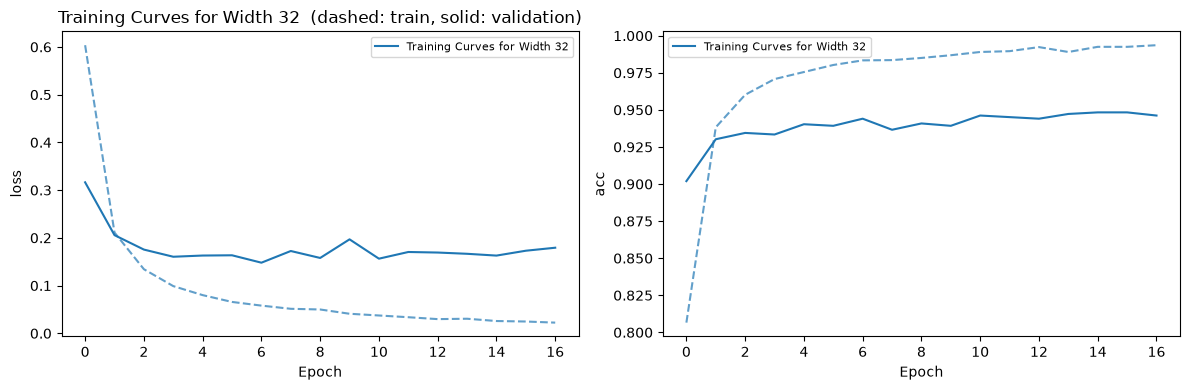

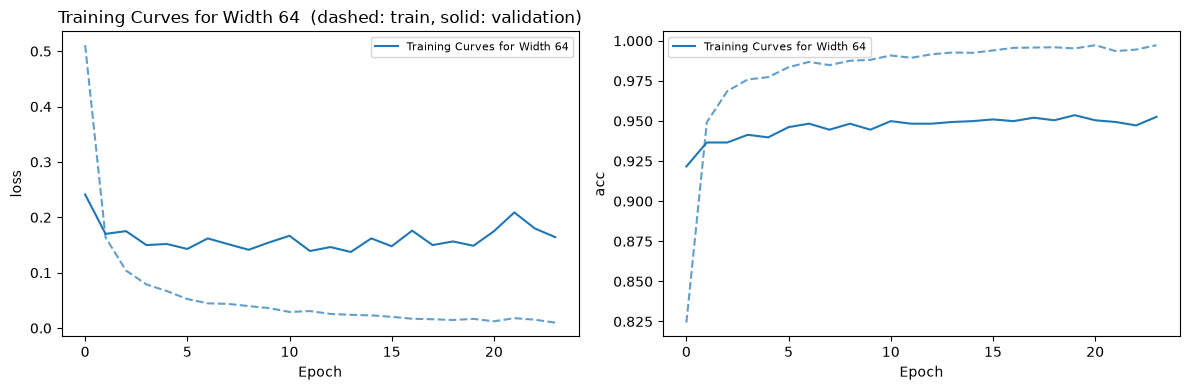

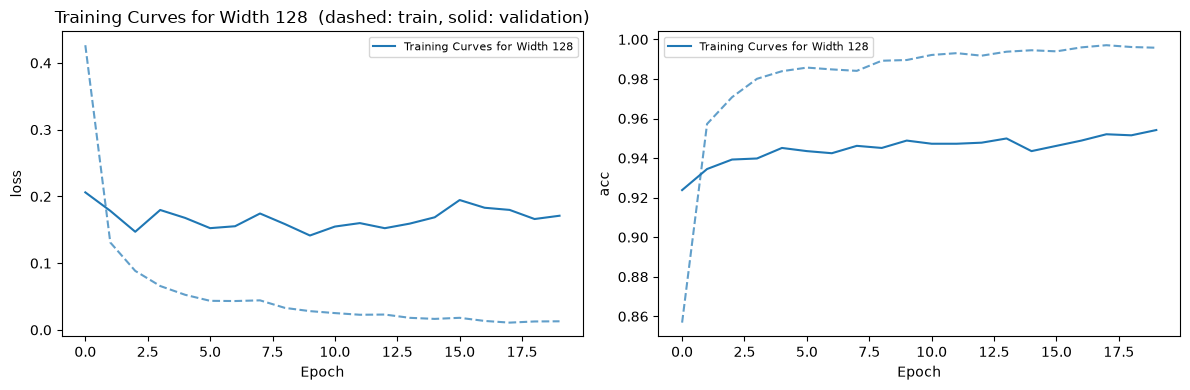

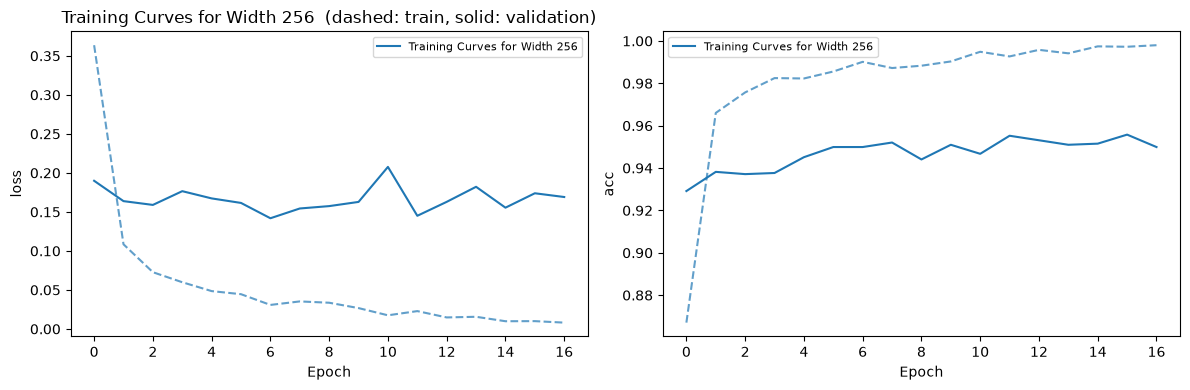

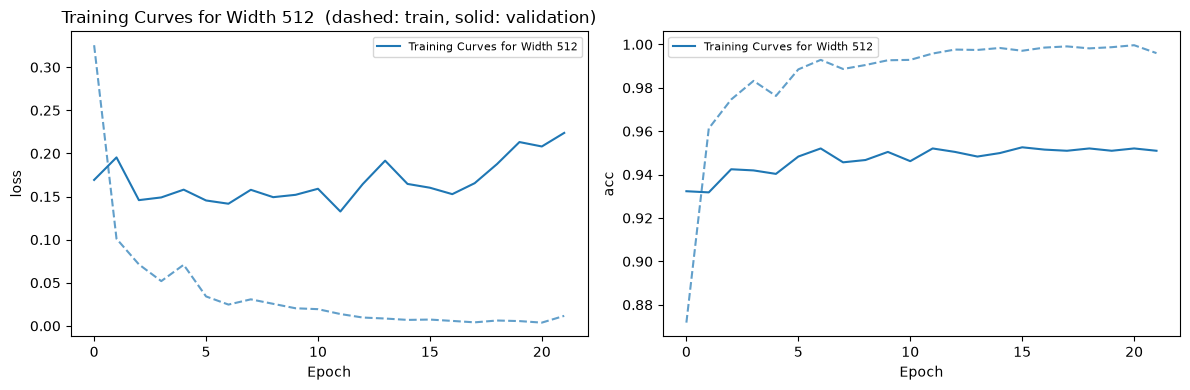

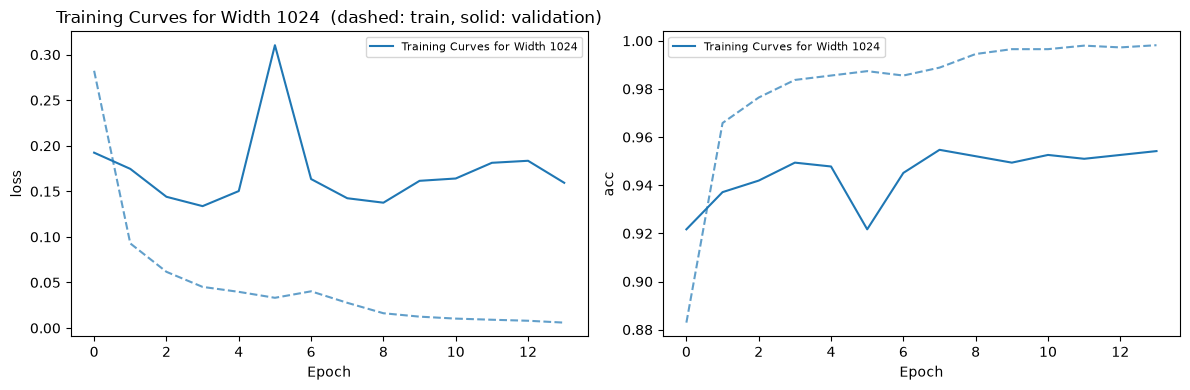

In [6]:
for w in widths:
    plot_curves(f"Training Curves for Width {w}", width_histories[f"Width {w}"])

The training loss converges quickly within a few epoch to 0. This is a clear sign of overfitting, notably because:
- even with the width-32 model, there are already around 18,000 parameters, more than the number of training samples.
- The validation errors saturate, thus generalization gap do not change between models of different width.

=> Thus, **regularization is needed**.

Compute time increases as the width increases as expected.

## Deeper Networks and Regularization

We now evaluate deeper networks with different activations.

As stated above, regularization is required to make the model not overfit, adding more layers won't solve this. So to pick some candidates, we add weight decay to our model.

As informed by results of the shallow network, we could try having Tanh activation in the first layer. As the features are 0-centered, Tanh preserves both positive and negative features without discarding negative values on the first pass like ReLU.

In the deeper layers, the ReLU family is probably better as its gradient does not saturate, prevents vanishing gradients, speeds up convergence, and induces sparse representations.

Early stopping triggered at epoch 23. Best val loss at epoch 3.
[(ReLU)              ] Seed   42 | Params:  72710 | Val Acc: 94.30% | Gap: 3.13%
Early stopping triggered at epoch 29. Best val loss at epoch 9.
[(ReLU)              ] Seed  123 | Params:  72710 | Val Acc: 94.89% | Gap: 4.24%
Early stopping triggered at epoch 23. Best val loss at epoch 3.
[(ReLU)              ] Seed  999 | Params:  72710 | Val Acc: 94.46% | Gap: 2.98%
Early stopping triggered at epoch 26. Best val loss at epoch 6.
[(ReLU)              ] Seed 1000 | Params:  72710 | Val Acc: 94.67% | Gap: 3.99%
Early stopping triggered at epoch 25. Best val loss at epoch 5.
[(ReLU)              ] Seed 2026 | Params:  72710 | Val Acc: 94.73% | Gap: 3.47%
Early stopping triggered at epoch 24. Best val loss at epoch 4.
[(ReLU) x2           ] Seed   42 | Params:  80582 | Val Acc: 94.83% | Gap: 2.87%
Early stopping triggered at epoch 23. Best val loss at epoch 3.
[(ReLU) x2           ] Seed  123 | Params:  80582 | Val Acc: 94.35

,Architecture,Hidden Layout,Parameters,Val Accuracy (Mean ± Std) (%),Val Macro F1 (Mean ± Std) (%),Gen Gap (Mean) (%),Avg Time/ep (ms)
0,(GELU) x4,"[256, 128, 64, 32]",187302,95.38 ± 0.28,95.84 ± 0.24,2.98,499.2
1,(ReLU) x4,"[256, 128, 64, 32]",187302,95.24 ± 0.22,95.72 ± 0.19,2.97,534.4
2,(ReLU) x3,"[256, 128, 64]",185414,95.28 ± 0.23,95.71 ± 0.21,2.97,473.2
3,(GELU) x3,"[256, 128, 64]",185414,95.15 ± 0.56,95.61 ± 0.53,2.86,454.4
4,(ReLU) x2,"[128, 64]",80582,95.02 ± 0.53,95.53 ± 0.44,3.13,175.7
5,(Tanh) x2,"[128, 64]",80582,95.04 ± 0.44,95.52 ± 0.41,3.21,369.9
6,(Tanh) - (ReLU) x3,"[256, 128, 64, 32]",187302,95.02 ± 0.49,95.51 ± 0.43,3.57,509.7
7,(Tanh) - (ReLU) x2,"[256, 128, 64]",185414,94.93 ± 0.38,95.38 ± 0.32,3.36,440.6
8,(Tanh) - (ReLU),"[128, 64]",80582,94.66 ± 0.40,95.20 ± 0.37,2.97,355.1
9,(ReLU),[128],72710,94.61 ± 0.23,95.18 ± 0.21,3.56,165.9


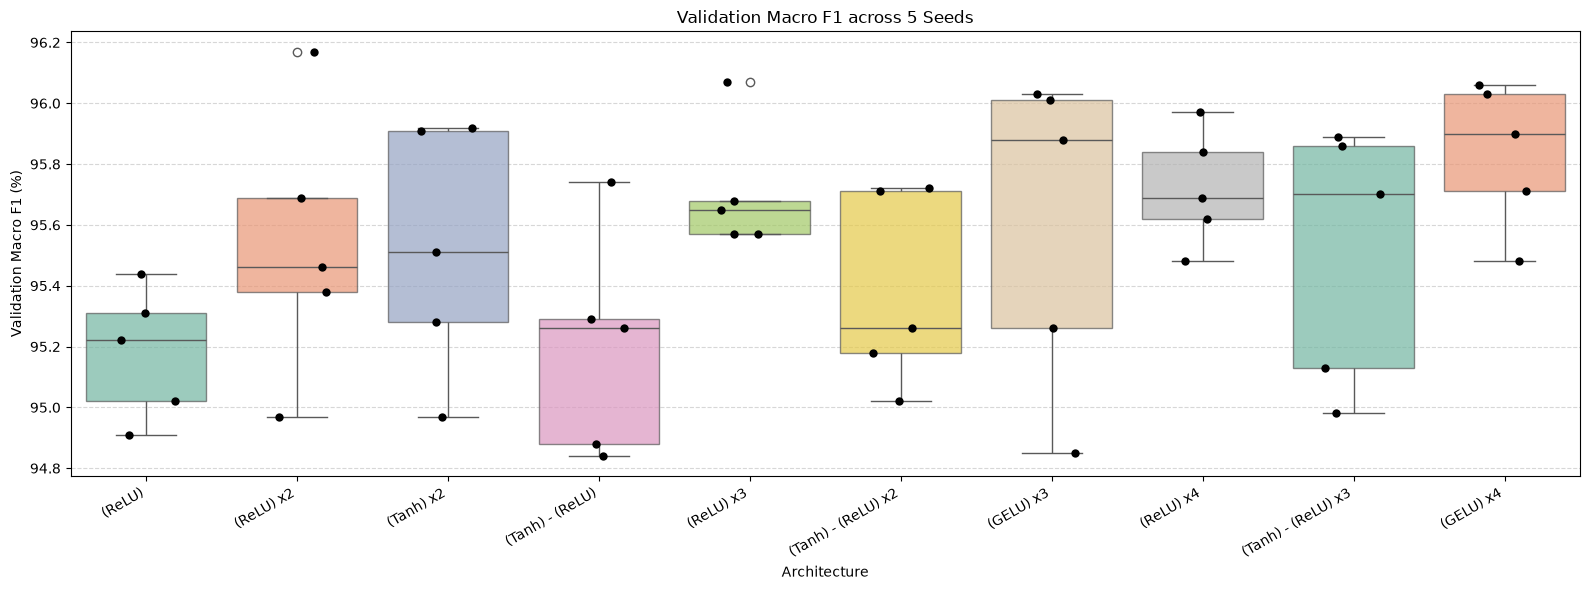

In [15]:
SEEDS = [42, 123, 999, 1000, 2026]
depth_configs = [
    # 1 layer reference
    {"name": "(ReLU)", "dims": [128], "acts": ["relu"]},
    # 2 layers
    {"name": "(ReLU) x2", "dims": [128, 64], "acts": ["relu", "relu"]},
    {"name": "(Tanh) x2", "dims": [128, 64], "acts": ["tanh", "tanh"]},
    {"name": "(Tanh) - (ReLU)", "dims": [128, 64], "acts": ["tanh", "relu"]},
    # 3 layers
    {"name": "(ReLU) x3", "dims": [256, 128, 64], "acts": ["relu", "relu", "relu"]},
    {"name": "(Tanh) - (ReLU) x2", "dims": [256, 128, 64], "acts": ["tanh", "relu", "relu"]},
    {"name": "(GELU) x3", "dims": [256, 128, 64], "acts": ["gelu", "gelu", "gelu"]},
    # 4 layers
    {"name": "(ReLU) x4", "dims": [256, 128, 64, 32], "acts": ["relu", "relu", "relu", "relu"]},
    {"name": "(Tanh) - (ReLU) x3", "dims": [256, 128, 64, 32], "acts": ["tanh", "relu", "relu", "relu"]},
    {"name": "(GELU) x4", "dims": [256, 128, 64, 32], "acts": ["gelu", "gelu", "gelu", "gelu"]},
]

all_seed_runs = []
seed_results = {cfg["name"]: {} for cfg in depth_configs}

for cfg in depth_configs:
    for seed in SEEDS:
        set_seed(seed)
        model = DeepMLP(input_dim=561, hidden_dims=cfg["dims"], num_classes=6, activations=cfg["acts"]).to(device)
        n_params = model.count_parameters()
        opt = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.0001)

        t0 = time.perf_counter()
        hist = train_model(
            model, train_loader, val_loader, criterion, opt,
            n_epochs=100, device=device, early_stopping_patience=20, verbose_every=0
        )
        elapsed = time.perf_counter() - t0

        best_ep = hist["best_epoch"]
        n_eps = len(hist["train_loss"])
        time_per_ep = (elapsed / n_eps) * 1000

        train_acc = hist["train_acc"][best_ep - 1] * 100
        train_loss = hist["train_loss"][best_ep - 1]
        val_acc = hist["val_acc"][best_ep - 1] * 100
        val_loss = hist["val_loss"][best_ep - 1]
        val_f1 = hist["val_f1"][best_ep - 1] * 100
        gen_gap = train_acc - val_acc

        run_data = {
            "Architecture": cfg["name"],
            "Hidden Layout": str(cfg["dims"]),
            "Seed": seed,
            "Parameters": n_params,
            "Best Epoch": f"{best_ep}/{n_eps}",
            "Train Acc (%)": round(train_acc, 2),
            "Train Loss": round(train_loss, 4),
            "Val Acc (%)": round(val_acc, 2),
            "Val Loss": round(val_loss, 4),
            "Val Macro F1 (%)": round(val_f1, 2),
            "Gen Gap (%)": round(gen_gap, 2),
            "Time/ep (ms)": round(time_per_ep, 1)
        }

        all_seed_runs.append(run_data)
        seed_results[cfg["name"]][seed] = run_data

        print(f"[{cfg['name']:<20}] Seed {seed:>4} | Params: {n_params:>6} | Val Acc: {val_acc:.2f}% | Gap: {gen_gap:.2f}%")

df_all_runs = pd.DataFrame(all_seed_runs)

summary_rows = []
for name, group in df_all_runs.groupby("Architecture", sort=False):
    accs = group["Val Acc (%)"]
    f1s = group["Val Macro F1 (%)"]
    gaps = group["Gen Gap (%)"]
    times = group["Time/ep (ms)"]
    layout = group["Hidden Layout"].iloc[0]
    params = group["Parameters"].iloc[0]

    summary_rows.append({
        "Architecture": name,
        "Hidden Layout": layout,
        "Parameters": params,
        "Val Accuracy (Mean ± Std) (%)": f"{accs.mean():.2f} ± {accs.std():.2f}",
        "Val Macro F1 (Mean ± Std) (%)": f"{f1s.mean():.2f} ± {f1s.std():.2f}",
        "Gen Gap (Mean) (%)": f"{gaps.mean():.2f}",
        "Avg Time/ep (ms)": f"{times.mean():.1f}",
        "_sort_f1": f1s.mean()
    })

df_summary = pd.DataFrame(summary_rows).sort_values(by="_sort_f1", ascending=False).drop(columns=["_sort_f1"]).reset_index(drop=True)

display(df_summary)

plt.figure(figsize=(16, 6))
sns.boxplot(
    data=df_all_runs, x="Architecture", y="Val Macro F1 (%)",
    hue="Architecture", palette="Set2", legend=False, boxprops=dict(alpha=0.7)
)
sns.stripplot(data=df_all_runs, x="Architecture", y="Val Macro F1 (%)", color="black", size=6, jitter=0.2)
plt.title(f"Validation Macro F1 across {len(SEEDS)} Seeds")
plt.xlabel("Architecture")
plt.ylabel("Validation Macro F1 (%)")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Adding regularization does give our models higher validation accuracy, we keep the configurations:
- GELU x4 (best performance),
- Tanh - ReLU x3 ,


reference, report

save norms, clip

- As instructed in the README: **an observed difference between two configurations that is smaller than this standard deviation ($pprox 0.5\%$) cannot be considered statistically significant.**
- Therefore, any claim that one architecture or hyperparameter is superior requires either a performance delta larger than the seed standard deviation or verification across multiple seeds.


activation, optimizer, lr.
learning curve, 2 F1, confusion, accuracy, multiple.

init
vanishing/exploding, pert not moving/slow/dont converge/noise?
under/over fit

test
